In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [4]:
df = pd.read_csv(r"C:\Users\Nishant\Downloads\india_petrol_price.csv")

In [5]:
df.shape

(10345, 8)

In [6]:
df.head()

,Date,State,Crude_Oil_Price_USD_per_Barrel,USD_INR_Exchange_Rate,Central_Tax_INR_per_Litre,State_Tax_INR_per_Litre,Refining_Transport_Cost_INR_per_Litre,Petrol_Price_INR_per_Litre
0,2018-09-18,Bihar,NaN,80.90,20.84,20.17,6.54,114.45
1,2024-03-11,Maharashtra,55.60,85.93,22.00,28.90,7.47,96.69
2,2023-03-28,Tamil Nadu,72.29,86.74,20.97,25.65,8.89,103.30
3,2021-07-06,Karnataka,61.97,81.76,20.29,26.50,10.24,97.77
4,2021-06-19,Kerala,59.34,82.88,19.21,18.90,7.12,89.11


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 8 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Date                                   10345 non-null  object 
 1   State                                  10345 non-null  object 
 2   Crude_Oil_Price_USD_per_Barrel         10035 non-null  float64
 3   USD_INR_Exchange_Rate                  10345 non-null  float64
 4   Central_Tax_INR_per_Litre              10345 non-null  float64
 5   State_Tax_INR_per_Litre                10035 non-null  float64
 6   Refining_Transport_Cost_INR_per_Litre  10345 non-null  float64
 7   Petrol_Price_INR_per_Litre             10345 non-null  float64
dtypes: float64(6), object(2)
memory usage: 646.7+ KB


In [8]:
df.describe()

,Crude_Oil_Price_USD_per_Barrel,USD_INR_Exchange_Rate,Central_Tax_INR_per_Litre,State_Tax_INR_per_Litre,Refining_Transport_Cost_INR_per_Litre,Petrol_Price_INR_per_Litre
count,10035.000000,10345.000000,10345.000000,10035.000000,10345.000000,10345.000000
mean,75.484295,82.059473,19.484097,22.146115,8.492167,99.588149
std,17.881691,3.497537,1.797071,4.396575,1.786881,11.580030
min,35.000000,72.000000,15.000000,12.000000,4.000000,65.000000
25%,63.105000,79.710000,18.280000,19.150000,7.280000,91.610000
50%,75.170000,82.090000,19.470000,22.080000,8.480000,99.410000
75%,87.610000,84.400000,20.700000,25.110000,9.690000,107.280000
max,130.000000,92.000000,25.000000,35.000000,14.000000,146.240000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

Date                                       0
State                                      0
Crude_Oil_Price_USD_per_Barrel           310
USD_INR_Exchange_Rate                      0
Central_Tax_INR_per_Litre                  0
State_Tax_INR_per_Litre                  310
Refining_Transport_Cost_INR_per_Litre      0
Petrol_Price_INR_per_Litre                 0
dtype: int64

#### Filling null values with median

In [13]:
df['Crude_Oil_Price_USD_per_Barrel'] = df['Crude_Oil_Price_USD_per_Barrel'].fillna(df['Crude_Oil_Price_USD_per_Barrel'].median())
df['State_Tax_INR_per_Litre'] = df['State_Tax_INR_per_Litre'].fillna(df['State_Tax_INR_per_Litre'].median())

In [14]:
df.isnull().sum()

Date                                     0
State                                    0
Crude_Oil_Price_USD_per_Barrel           0
USD_INR_Exchange_Rate                    0
Central_Tax_INR_per_Litre                0
State_Tax_INR_per_Litre                  0
Refining_Transport_Cost_INR_per_Litre    0
Petrol_Price_INR_per_Litre               0
dtype: int64

In [ ]:
df.corr(numeric_only=True)

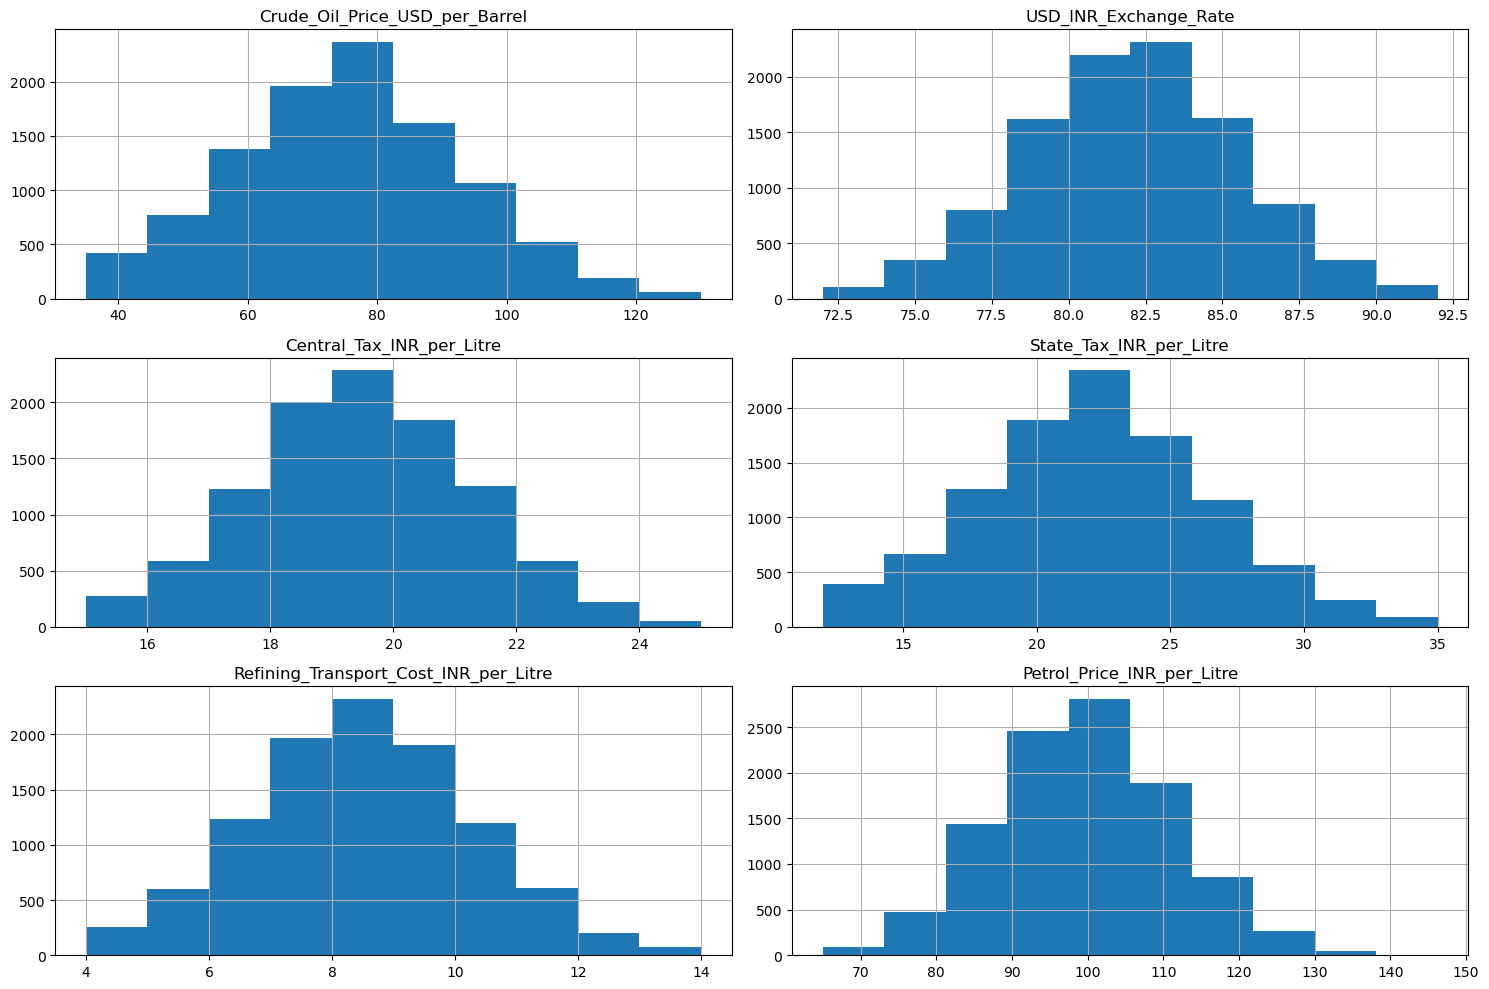

In [15]:
df.hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

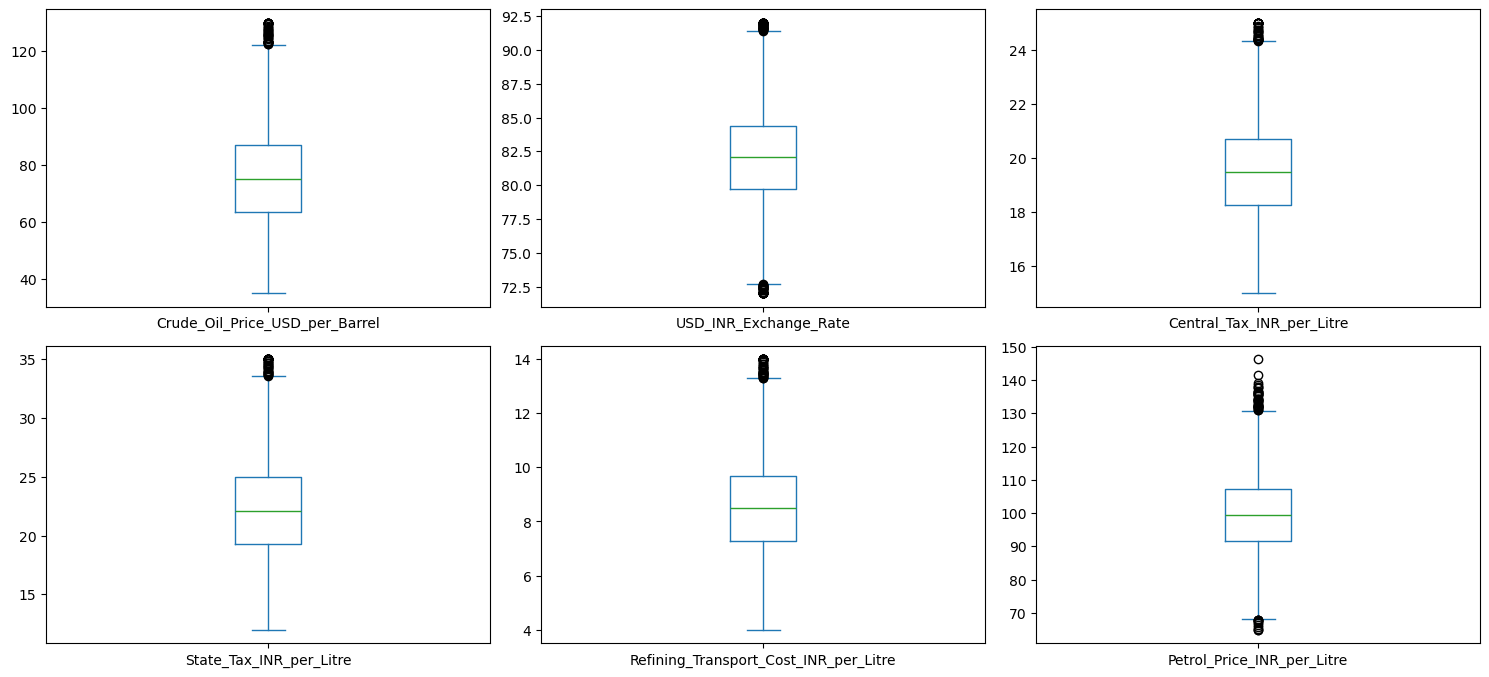

In [16]:
df.select_dtypes(include='number').plot(kind='box', subplots=True, layout=(3, 3), figsize=(15, 10))
plt.tight_layout()
plt.show()

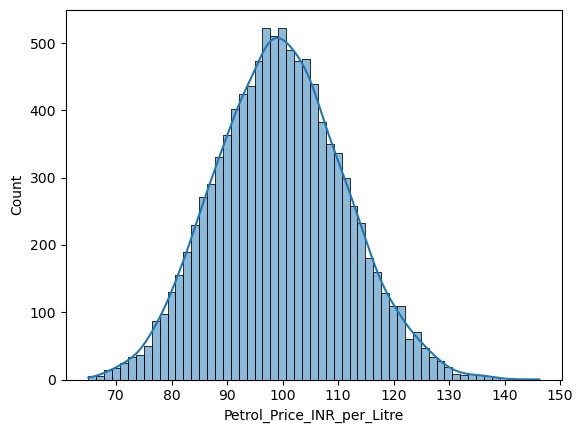

In [17]:
sns.histplot(df['Petrol_Price_INR_per_Litre'], kde=True)
plt.show()

#### Defining X and y variables

In [19]:
X = df.drop('Petrol_Price_INR_per_Litre', axis=1)
y = df['Petrol_Price_INR_per_Litre']

#### Converting categorical into numerical columns

In [20]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

#### Splitting dataset into training and testing 

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### Training linear regression model

In [24]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [25]:
y_pred = model.predict(X_test)

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
print("MAE:", mean_absolute_error(y_test, y_pred));
print("MSE:", mean_squared_error(y_test, y_pred)); 
print("RMSE:", mean_squared_error(y_test, y_pred)**0.5)
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 2.5715563842647695
MSE: 12.516119858236612
RMSE: 3.5378128636541266
R2 Score: 0.9017859990420669


#### Plotting the residuals

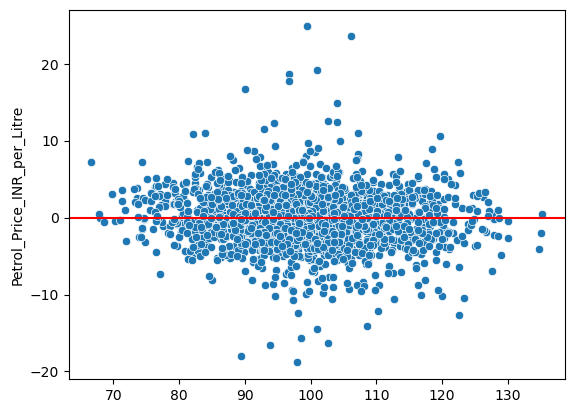

In [29]:
residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, color='red'); plt.show()

#### Plotting actual vs predicted prices of petrol

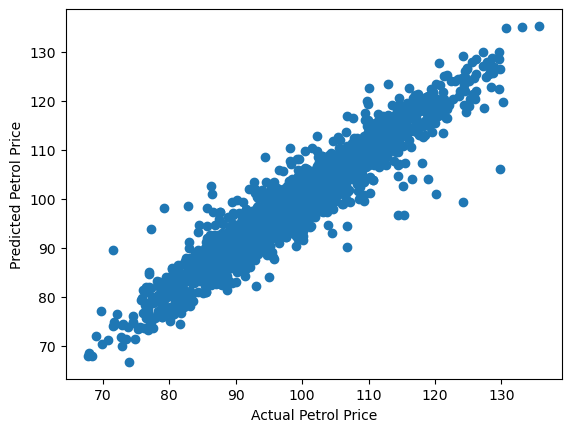

In [31]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Petrol Price'); plt.ylabel('Predicted Petrol Price'); plt.show()

#### Linear regression assumption

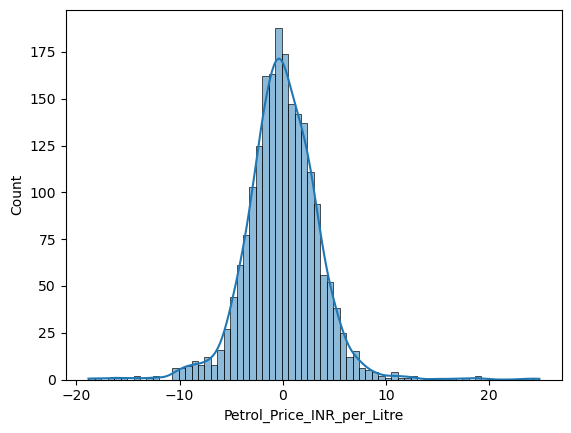

In [33]:
sns.histplot(residuals, kde=True)
plt.show()

In [35]:
from sklearn.model_selection import cross_val_score
cross_val_score(model, X, y, cv=5, scoring='r2')

array([0.90806607, 0.90061963, 0.91480854, 0.90148606, 0.91122549])

#### Applying ridge regression

In [37]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


#### Evaluating ridge regression using r2 score

In [38]:
y_ridge = ridge.predict(X_test)
print("Ridge R2 Score:", r2_score(y_test, y_ridge))

Ridge R2 Score: 0.9217217868645411


#### Applying lassso regression

In [39]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=0.1).fit(X_train, y_train)

#### Evaluating lasso regression

In [40]:
y_lasso = lasso.predict(X_test)
print("Lasso R2 Score:", r2_score(y_test, y_lasso))

Lasso R2 Score: 0.9219775976023474


#### Applying elasticnet regression

In [42]:
from sklearn.linear_model import ElasticNet
elastic = ElasticNet(alpha=0.1, l1_ratio=0.5).fit(X_train, y_train)

#### Evaluating elasticnet regression

In [43]:
y_elastic = elastic.predict(X_test)
print("ElasticNet R2 Score:", r2_score(y_test, y_elastic))

ElasticNet R2 Score: 0.9214128061157006


#### Comparing models

In [47]:
print("Linear:", r2_score(y_test, y_pred), 
      "Ridge:", r2_score(y_test, y_ridge), 
      "Lasso:", r2_score(y_test, y_lasso), 
      "ElasticNet:", r2_score(y_test, y_elastic))

Linear: 0.9017859990420669 Ridge: 0.9217217868645411 Lasso: 0.9219775976023474 ElasticNet: 0.9214128061157006


#### Tuning ridge regression alpha


In [49]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(Ridge(), {'alpha': [0.01, 0.1, 1, 10, 100]}, cv=5, scoring='r2')
grid.fit(X_train, y_train)

,estimator,Ridge()
,param_grid,"{'alpha': [0.01, 0.1, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,10


#### Best alpha and cross validation r2 score

In [51]:
print("Best Alpha:", grid.best_params_)
print("Best CV R2:", grid.best_score_)

Best Alpha: {'alpha': 10}
Best CV R2: 0.9336393929296426


#### Training final ridge model

In [52]:
best_ridge = Ridge(alpha=grid.best_params_['alpha'])
best_ridge.fit(X_train, y_train)

,alpha,10
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


#### Evaluating final ridge model

In [53]:
y_best = best_ridge.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_best), 
      "MSE:", mean_squared_error(y_test, y_best), 
      "RMSE:", mean_squared_error(y_test, y_best)**0.5, 
      "R2:", r2_score(y_test, y_best))

MAE: 2.0721552180424028 MSE: 8.427509408517704 RMSE: 2.90301729387162 R2: 0.9338693279949333


#### Actual vs predicted value

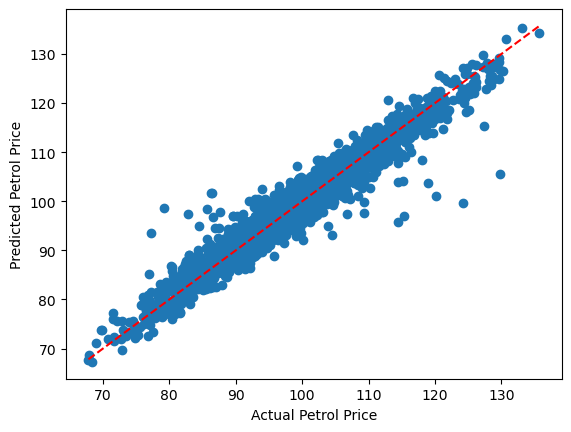

In [59]:
plt.scatter(y_test, y_best)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Petrol Price');
plt.ylabel('Predicted Petrol Price'); 
plt.show()

In [56]:
print("Best Ridge Alpha:", grid.best_params_['alpha'])
print("Final Ridge R2:", r2_score(y_test, y_best))

Best Ridge Alpha: 10
Final Ridge R2: 0.9338693279949333


#### Conclusion: 
#### The Ridge Regression model achieved an R² score of 93.39%, with an MAE of 2.07, MSE of 8.43, and RMSE of 2.90. The model explains approximately 93.39% of the variation in petrol prices, demonstrating a strong fit to the test data.